# 03. 정제 — 전체 11단계 중 3단계

이 노트북은 작업하며 주고받은 답변(✍️ 칸과 클로드의 답변)을 빼고, 코드 · 결과 · 물음마다의 결론(📌)만 남긴 판이다. 단계마다 한 일과 정한 것은 README 「전체 흐름」에 있다.

# 준비 셀 둘

아래 두 셀을 먼저 돌립니다. 물음 셋이 다 이 두 셀에서 만든 표를 씁니다. 준비 ①은 파일을 읽는 함수를 만들고, 준비 ②는 세 해를 한 표로 붙입니다. 결과를 거의 안 찍으므로 적는 칸을 두지 않았습니다.

In [99]:
# 3단계 정제 · 준비 ①
import os                                     # 폴더·파일 경로를 다루는 기본 모듈
import numpy as np                            # 평균·제곱근 같은 숫자 계산
import pandas as pd                           # 표(데이터프레임)를 다루는 라이브러리
import matplotlib.pyplot as plt               # 그림 그리는 라이브러리
plt.rcParams["font.family"] = "AppleGothic"   # 맥에서 그림 속 한글이 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False    # 마이너스 부호가 깨지지 않게
pd.set_option("display.width", 200)           # 표가 줄바꿈 없이 넓게 보이게
pd.set_option("display.max_columns", 50)      # 열이 많아도 생략하지 않게
pd.set_option("display.unicode.east_asian_width", True)   # 한글 열 이름을 두 칸으로 세어 표가 어긋나지 않게

ROOT = os.getcwd()                            # 지금 폴더(보통 notebooks/)에서 시작해
while not os.path.isdir(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
    ROOT = os.path.dirname(ROOT)              # data 폴더가 보일 때까지 위로 = 프로젝트 루트
RAW = os.path.join(ROOT, "data", "raw")       # 원자료 폴더

버린날 = []                                     # 192행이 아니어서 버린 날짜를 담아 둘 목록

def load_kpx(year):                                                     # KPX 연간 파일 한 해를 읽어 열 이름을 통일한다
    folder = os.path.join(RAW, "kpx")
    name = [f for f in os.listdir(folder) if f"{year}1231" in f][0]      # 파일명에 20231231 같은 기준일이 들어 있다
    df = pd.read_csv(os.path.join(folder, name), encoding="utf-8-sig")   # 맨 앞 BOM이 있는 utf-8
    df.columns = ["date", "hour", "fuel", "cap_mw", "mwh"]              # 해마다 열 이름이 달라서 순서로 통일한다
    df["fuel"] = df["fuel"].str.strip()                                  # 연료 이름 앞뒤 공백 제거
    df["ts"] = pd.to_datetime(df["date"]) + pd.to_timedelta(df["hour"].astype(int) - 1, unit="h")  # 1~24시를 0~23시 시각으로
    return df

def pick(df, fuel, col, newname):               # 연료 하나에서 '시각 + 값' 두 열만 떼 온다
    d = df[df["fuel"] == fuel]                  # 그 연료의 행만 남긴다
    return d[["ts", col]].rename(columns={col: newname})    # 열 이름을 알아보기 쉽게 바꾼다

def load_api_year(year):                        # API 일별 파일을 한 해치 모아 붙인다
    folder = os.path.join(RAW, "api")
    files = [f for f in sorted(os.listdir(folder))                       # 파일 이름이 20240102.csv 꼴이라
             if f.startswith(str(year)) and f.endswith(".csv")]          # 앞 네 자리로 그 해만 고른다
    parts = []
    for f in files:
        q = os.path.join(folder, f)
        if os.path.getsize(q) < 100:            # 100바이트 미만 = 0행 파일(2024-02-29 — API에 그날이 없다)
            continue                            # 건너뛴다
        one = pd.read_csv(q, encoding="utf-8-sig")   # 하루치를 읽는다
        if len(one) != 192:                     # 정상은 연료 8종 × 24시간 = 192행이다
            버린날.append(f[:8])                 # 192행이 아니면 날짜만 적어 두고
            continue                            # 그 하루는 쓰지 않는다 (2024년 8월 1일부터 31일까지가 여기 걸린다)
        parts.append(one)                       # 정상인 하루만 모은다
    a = pd.concat(parts, ignore_index=True)     # 하루치 파일들을 위아래로 붙인다
    a = a.rename(columns={"fuelTpCd": "fuel"})  # API의 연료 열 이름을 연간 파일과 같게
    a["ts"] = pd.to_datetime(a["tradeYmd"].astype(str)) + pd.to_timedelta(a["tradeNo"].astype(int) - 1, unit="h")
    return a                                    # tradeNo가 1~24시라 연간 파일과 같은 방식으로 0~23시로

print("프로젝트 루트:", ROOT)                    # 경로가 맞는지만 확인한다


프로젝트 루트: /Users/kimchangju/vs코드 /개인 프로젝트/lng-project


In [100]:
# 3단계 정제 · 준비 ②
frames = []
for y in (2023, 2025):                          # 이 두 해는 연간 파일 하나에 LNG·원자력·태양광이 다 있다
    k = load_kpx(y)
    t = pick(k, "LNG", "mwh", "lng_mwh") \
        .merge(pick(k, "원자력", "mwh", "nuke_mwh"), on="ts", how="left") \
        .merge(pick(k, "태양광", "cap_mw", "solar_cap_mw"), on="ts", how="left")   # 태양광은 발전량이 아니라 설비용량(MW)
    frames.append(t)

k24 = load_kpx(2024)                            # 2024 연간 파일 — 태양광 설비용량은 여기 있다
a24 = load_api_year(2024)                       # 2024 API — LNG·원자력은 여기 있다(API에는 설비용량 열이 없다)
t24 = pick(a24, "LNG", "amgo", "lng_mwh") \
      .merge(pick(a24, "원자력", "amgo", "nuke_mwh"), on="ts", how="left") \
      .merge(pick(k24, "태양광", "cap_mw", "solar_cap_mw"), on="ts", how="left")
frames.append(t24)

tbl = pd.concat(frames, ignore_index=True).sort_values("ts").reset_index(drop=True)  # 세 해를 시간순으로 한 장에

asos_dir = os.path.join(RAW, "asos")            # 기상(ASOS 서울 108)을 같은 시각에 붙인다
asos = pd.concat([pd.read_csv(os.path.join(asos_dir, f), encoding="utf-8-sig")
                  for f in sorted(os.listdir(asos_dir)) if f.endswith(".csv")], ignore_index=True)
asos["ts"] = pd.to_datetime(asos["tm"])         # '2023-01-01 00:00' 글자를 시각으로
tbl = tbl.merge(asos[["ts", "ta", "hm", "icsr"]], on="ts", how="left")   # 기온·습도·일사
tbl["icsr"] = tbl["icsr"].fillna(0)             # 일사는 해가 없을 때 비는 것이 정상이므로 0으로

tbl["year"] = tbl["ts"].dt.year                 # 달력에서 만드는 파생변수 — 2023 / 2024 / 2025
tbl["month"] = tbl["ts"].dt.month               # 1~12월
tbl["hour24"] = tbl["ts"].dt.hour               # 0~23시
tbl["dow"] = tbl["ts"].dt.dayofweek             # 요일 0=월 … 6=일
tbl["is_weekend"] = (tbl["dow"] >= 5).astype(int)   # 토·일이면 1

if 버린날:                                       # 버린 날이 있으면 먼저 알린다
    print(f"192행이 아니어서 버린 날 {len(버린날)}일: {버린날[0]} ~ {버린날[-1]}")
    print("  2024년 8월은 API에 원자력·무연탄·유전이 빠지고 남은 연료의 값도 잘못 들어 있다(2026-09-15 재요청으로 확인).\n")
print("표 모양 (행, 열):", tbl.shape)
print("\n해별 행 수와 기간")
print(tbl.groupby("year").agg(행수=("ts", "size"), 시작=("ts", "min"), 끝=("ts", "max")))
print("\n붙이다가 빈 칸이 생겼는지 — 전부 0이어야 같은 시각끼리 빠짐없이 붙은 것이다")
print(tbl.isna().sum().to_string())

학습해 = [2023, 2024]   # 학습에 쓸 해. 2024년은 8월 한 달과 2월 29일이 빠져 334일이다
train = tbl[tbl["year"].isin(학습해)]            # 학습 기간 — 재료를 뽑는 데 쓴다
valid = tbl[tbl["year"] == 2025]                # 채점 기간 — 2025

print("\n학습 기간", 학습해, "—", len(train), "행 / 채점 2025 —", len(valid), "행")


192행이 아니어서 버린 날 31일: 20240801 ~ 20240831
  2024년 8월은 API에 원자력·무연탄·유전이 빠지고 남은 연료의 값도 잘못 들어 있다(2026-09-15 재요청으로 확인).

표 모양 (행, 열): (25536, 12)

해별 행 수와 기간
      행수       시작                  끝
year                                     
2023  8760 2023-01-01 2023-12-31 23:00:00
2024  8016 2024-01-01 2024-12-31 23:00:00
2025  8760 2025-01-01 2025-12-31 23:00:00

붙이다가 빈 칸이 생겼는지 — 전부 0이어야 같은 시각끼리 빠짐없이 붙은 것이다
ts              0
lng_mwh         0
nuke_mwh        0
solar_cap_mw    0
ta              0
hm              0
icsr            0
year            0
month           0
hour24          0
dow             0
is_weekend      0

학습 기간 [2023, 2024] — 16776 행 / 채점 2025 — 8760 행


# 물음 1 — 2024년 8월과 2026년 5월을 어떻게 할까

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 1 결론

**왜 생긴 물음인가** — 2단계에서 2024년 8월과 2026년 5월 2~17일의 API 값이 깨져 온 것을 확인했고, 2단계 닫는 칸 ③에서 「24년 8월 보고 판단하고, 그다음 26년 5월」로 순서를 정했다. 두 기간을 뺄지 남길지 정한 물음이다.

### 결정 — 2024년 8월 1~31일은 학습에서 빼고, 2026년 5월 2~17일은 9단계 비교에서 뺀다

**결정 근거** — API에 같은 날짜를 다시 요청해도 같은 값이 왔고(2024년 8월은 09-15, 2026년 5월은 09-19), EPSIS 월별 표에는 두 기간 다 정상으로 들어 있어서 실제 발전이 아니라 기록의 문제다. 1-다·1-라에서 5월 1일은 정상, 2일은 120행(LNG 하루 합 1,047), 3~16일은 48행(LNG 없음), 17일은 0행이었다. 판단은 「1-다 · 1-라」 아래 「✍️ 내 답변」 1·2·3에 적었다.

**남은 것** — 8월은 2023년 한 해치만 배운다. 7단계(모델을 만들고 기준선과 비교하는 단계)에서 달별 오차를 볼 때 8월은 따로 보거나 한계에 적는다(3단계 닫는 칸 2).

</div>

## 1-가

**무엇을 보는 셀인가.** 2023·2024·2025년 원자료가 달마다 어떻게 생겼는지 한 표로 봅니다. 2023·2025년은 KPX 연간 파일에서, 2024년은 API 일별 파일에서 세어 같은 표에 놓았습니다.

In [101]:
# 3단계 정제 · 1-가
표 = pd.DataFrame(index=range(1, 13))                        # 행은 1월부터 12월까지
표.index.name = "월"

for y in (2023, 2025):                                       # 이 두 해는 연간 파일 하나로 들어왔다
    k = load_kpx(y)                                          # 그 해 파일 전체(모든 연료)
    k["월"] = pd.to_datetime(k["date"]).dt.month             # 거래일자에서 월만 꺼낸다
    표[f"{str(y)[2:]} LNG"] = k[k["fuel"] == "LNG"].groupby("월").size()   # 그 달에 LNG 값이 몇 시각 들어 있나
    표[f"{str(y)[2:]} 종수"] = k.groupby("월")["fuel"].nunique()    # 그 달에 연료가 몇 종류 들어 있나

folder = os.path.join(RAW, "api")                            # 2024년은 하루에 파일 하나씩 있다
집계 = {}
for f in sorted(x for x in os.listdir(folder) if x.startswith("2024") and x.endswith(".csv")):
    q = os.path.join(folder, f)
    m = int(f[4:6])                                          # 파일 이름 20240801에서 08을 꺼낸다
    d = 집계.setdefault(m, {"날수": 0, "정상": 0, "종수": 0})
    d["날수"] += 1                                            # 그 달에 파일이 몇 개 있나
    if os.path.getsize(q) >= 100:                            # 100바이트보다 작으면 0행 파일이다
        one = pd.read_csv(q, encoding="utf-8-sig")
        if len(one) == 192:                                  # 정상은 연료 8종 × 24시간 = 192행
            d["정상"] += 1
        d["종수"] = max(d["종수"], one["fuelTpCd"].nunique())  # 그 달에 나온 연료 종류 수
표["24 날수"] = pd.Series({m: d["날수"] for m, d in 집계.items()})
표["24 정상"] = pd.Series({m: d["정상"] for m, d in 집계.items()})
표["24 종수"] = pd.Series({m: d["종수"] for m, d in 집계.items()})

표 = 표[["23 LNG", "23 종수", "24 날수", "24 정상", "24 종수", "25 LNG", "25 종수"]]                      # 해 순서대로 열을 늘어놓는다
print("2023·2024·2025년 원자료가 달마다 어떻게 생겼는지")
print("  LNG = 그 달에 LNG 값이 있는 시각 수 · 종수 = 그 달에 나온 연료 종류 수 · 날수 = 파일 수 · 정상 = 192행인 날")
print("  2023·2025는 연간 파일이라 하루 행 수를 따지지 않는다. 2024는 API라 하루 192행이 정상이다.")
print(표.to_string())

2023·2024·2025년 원자료가 달마다 어떻게 생겼는지
  LNG = 그 달에 LNG 값이 있는 시각 수 · 종수 = 그 달에 나온 연료 종류 수 · 날수 = 파일 수 · 정상 = 192행인 날
  2023·2025는 연간 파일이라 하루 행 수를 따지지 않는다. 2024는 API라 하루 192행이 정상이다.
    23 LNG  23 종수  24 날수  24 정상  24 종수  25 LNG  25 종수
월                                                             
1      744       20       31       31        8     744       25
2      672       20       29       28        8     672       25
3      744       20       31       31        8     744       26
4      720       20       30       30        8     720       26
5      744       20       31       31        8     744       26
6      720       20       30       30        8     720       26
7      744       21       31       31        8     744       26
8      744       21       31        0        5     744       26
9      720       21       30       30        8     720       25
10     744       21       31       31        8     744       26
11     720       21       30       30        8     720       26
12 

## 1-나

**무엇을 보는 셀인가.** 2026년 원자료가 달마다 어떻게 생겼는지 봅니다. 하루 192행이 정상입니다.

In [102]:
# 3단계 정제 · 1-나
folder = os.path.join(RAW, "api")
집계26 = {}
for f in sorted(x for x in os.listdir(folder) if x.startswith("2026") and x.endswith(".csv")):
    q = os.path.join(folder, f)
    m = int(f[4:6])                                          # 파일 이름 20260502에서 05를 꺼낸다
    n = 0 if os.path.getsize(q) < 100 else len(pd.read_csv(q, encoding="utf-8-sig"))   # 그 파일의 행 수
    d = 집계26.setdefault(m, {"받은 날 수": 0, "192행인 날": 0, "나온 행 수": set()})
    d["받은 날 수"] += 1
    if n == 192:
        d["192행인 날"] += 1
    d["나온 행 수"].add(n)                                     # 그 달에 어떤 행 수들이 나왔는지 모아 둔다

표26 = pd.DataFrame([{"월": m, "받은 날 수": d["받은 날 수"], "192행인 날": d["192행인 날"],
                      "그 달에 나온 하루 행 수": ", ".join(str(x) for x in sorted(d["나온 행 수"]))}
                     for m, d in sorted(집계26.items())])
print("2026년 원자료가 달마다 어떻게 생겼는지 — 하루 192행이 정상이다")
print(표26.to_string(index=False))

2026년 원자료가 달마다 어떻게 생겼는지 — 하루 192행이 정상이다
 월  받은 날 수  192행인 날 그 달에 나온 하루 행 수
  1          31          31                     192
  2          28          28                     192
  3          31          31                     192
  4          30          30                     192
  5          31          15         0, 48, 120, 192
  6          30          30                     192
  7          10          10                     192


## 1-다 · 1-라

**무엇을 보는 셀인가.** 2026년 5월을 하루씩 봅니다. 1-다가 1일부터 16일까지, 1-라가 17일부터 31일까지입니다. 31일을 한 셀에 넣으면 출력이 30줄을 넘어 VS Code가 가운데를 접습니다. 1-라는 1-다가 만든 표를 쓰므로 1-다를 먼저 돌립니다.

In [103]:
# 3단계 정제 · 1-다
folder = os.path.join(RAW, "api")
행 = []
for f in sorted(x for x in os.listdir(folder) if x.startswith("202605") and x.endswith(".csv")):
    q = os.path.join(folder, f)
    if os.path.getsize(q) < 100:                             # 0행 파일이면 셀 것이 없다
        행.append({"날짜": f[:8], "행 수": 0, "연료 종수": 0, "LNG 하루 합(MWh)": 0})
        continue
    one = pd.read_csv(q, encoding="utf-8-sig")
    lng = one[one["fuelTpCd"] == "LNG"]["amgo"].sum()         # 그날 LNG 24시각을 다 더한다
    행.append({"날짜": f[:8], "행 수": len(one), "연료 종수": one["fuelTpCd"].nunique(),
               "LNG 하루 합(MWh)": round(lng)})
표5 = pd.DataFrame(행)                                        # 1-라에서도 이 표를 쓴다

print("2026년 5월 1일부터 16일까지 — 하루씩 (정상은 192행)")
print(표5.iloc[:16].to_string(index=False))

2026년 5월 1일부터 16일까지 — 하루씩 (정상은 192행)
    날짜  행 수  연료 종수  LNG 하루 합(MWh)
20260501    192          8            328788
20260502    120          5              1047
20260503     48          2                 0
20260504     48          2                 0
20260505     48          2                 0
20260506     48          2                 0
20260507     48          2                 0
20260508     48          2                 0
20260509     48          2                 0
20260510     48          2                 0
20260511     48          2                 0
20260512     48          2                 0
20260513     48          2                 0
20260514     48          2                 0
20260515     48          2                 0
20260516     48          2                 0


In [104]:
# 3단계 정제 · 1-라
print("2026년 5월 17일부터 31일까지 — 하루씩 (정상은 192행)")
print(표5.iloc[16:].to_string(index=False))

2026년 5월 17일부터 31일까지 — 하루씩 (정상은 192행)
    날짜  행 수  연료 종수  LNG 하루 합(MWh)
20260517      0          0                 0
20260518    192          8            408362
20260519    192          8            410620
20260520    192          8            444952
20260521    192          8            426217
20260522    192          8            347491
20260523    192          8            343975
20260524    192          8            317591
20260525    192          8            323387
20260526    192          8            459265
20260527    192          8            477905
20260528    192          8            451864
20260529    192          8            407954
20260530    192          8            347740
20260531    192          8            302093


# 물음 2 — 태양광 설비용량을 어떻게 할까

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 2 결론

**왜 생긴 물음인가** — 2단계 닫는 칸 ①에 「태양광 설비가 실제로 늘어나면 25년도 데이터를 그대로 쓸 수는 없을 것 같은데」라고 적었다. 학습(2023·2024년)과 채점(2025년)의 설비용량이 한 값도 겹치지 않아서, 값에 문제가 있는지 확인하려고 연 물음이다.

### 결정 — 설비용량 값 자체에는 문제가 없다. 설비용량 대신 태양광 발전량을 쓰는 쪽으로 방향을 정했다 (확정은 6단계)

**결정 근거** — 2-다에서 태양광을 설비용량으로 넣으면 채점 값의 학습 밖 비율이 100%인데, 발전량으로 바꾸면 0.3%로 떨어졌다. LNG와 원자력은 발전량인데 태양광만 설비용량이라 같은 것을 보고 있지 않았다(2-가 「✍️ 읽고 나서」 아래 09-19 채팅). 설비용량 값 자체에는 빈 칸도 잘못된 값도 없었다(2-나 「✍️ 내 답변」 1의 「결측은 없다」). 판단은 2-다 아래 「✍️ 내 답변」에 적었다(「발전량으로 사용해야겠다」).

**남은 것** — 5단계 물음 3에서 이어 봤다. 2026년에는 태양광 발전량이 따로 없어서(API가 「신재생·기타」로 묶어 준다) 일사 한 열을 넣는 쪽을 제안하고 있다.

→ **이어진 곳(10-05)** — 5단계 물음 3에서 태양광 대신 일사 한 열을 넣기로 정했다(09-27). 6단계 물음 3에서 2025·2026년 일사가 2023·2024년에 본 범위 안이고, 2024년에는 일사 한 열이 늘어난 패널을 못 따라간다는 흔적이 없는 것을 확인해 그대로 7단계로 넘겼다(10-04).

</div>

## 2-가

**무엇을 보는 셀인가.** 태양광 설비용량이 달마다·해마다 얼마였는지 봅니다.

In [105]:
# 3단계 정제 · 2-가
달별 = tbl.pivot_table(index="month", columns="year", values="solar_cap_mw", aggfunc="max").round(0)
달별.columns = [f"{c}년" for c in 달별.columns]                  # 열 이름을 2023년 · 2024년 · 2025년으로
달별.index.name = "월"
print("[표 1] 태양광 설비용량(MW) — 달마다 그 달의 최대")
print(달별.to_string())

해별 = tbl.groupby("year")["solar_cap_mw"].agg(["min", "max"]).round(0)   # 해마다 최소와 최대
해별["앞 해 최대보다"] = 해별["max"].diff().round(0)               # 앞 해 최대보다 얼마나 늘었나
print("\n[표 2] 해마다 최소·최대와, 앞 해 최대보다 얼마나 늘었나")
print(해별.to_string())

[표 1] 태양광 설비용량(MW) — 달마다 그 달의 최대
    2023년  2024년   2025년
월                         
1   7310.0  8691.0   9662.0
2   7356.0  8730.0   9716.0
3   7440.0  8789.0   9732.0
4   7517.0  8838.0   9881.0
5   7613.0  8938.0   9967.0
6   7661.0  8891.0  10085.0
7   8075.0  8955.0  10254.0
8   8187.0     NaN  10303.0
9   8275.0  9218.0  10312.0
10  8376.0  9317.0  10379.0
11  8446.0  9485.0  10454.0
12  8563.0  9615.0  10834.0

[표 2] 해마다 최소·최대와, 앞 해 최대보다 얼마나 늘었나
         min      max  앞 해 최대보다
year                                 
2023  6916.0   8563.0             NaN
2024  8563.0   9615.0          1052.0
2025  9616.0  10834.0          1219.0


## 2-나

**무엇을 보는 셀인가.** 후보 입력 아홉 개가 학습 기간과 채점 기간에서 각각 어디부터 어디까지인지, 채점 기간의 값이 학습 범위를 얼마나 벗어나는지 봅니다. 마지막 열이 그 비율입니다.

In [106]:
# 3단계 정제 · 2-나
설명 = {                                          # 열 이름 → (뜻, 단위)
    "nuke_mwh":     ("같은 시각 원자력 발전량", "MWh"),
    "solar_cap_mw": ("그 시각 태양광 설비용량 = 설치된 정격출력의 합", "MW"),
    "ta":           ("서울 108 기온", "℃"),
    "hm":           ("서울 108 습도", "%"),
    "icsr":         ("서울 108 일사량", "MJ/m²"),
    "hour24":       ("하루 안의 시각 0~23", "시"),
    "dow":          ("요일 0=월 … 6=일", "-"),
    "is_weekend":   ("토·일이면 1, 아니면 0", "0/1"),
    "month":        ("1~12월", "월"),
}
표1 = [{"열 이름": c, "뜻": 뜻, "단위": 단위, "빈 칸": int(tbl[c].isna().sum())}
       for c, (뜻, 단위) in 설명.items()]
print("[표 1] 후보 입력 아홉 개가 무엇인가 — 한 줄이 열 하나다")
print(pd.DataFrame(표1).to_string(index=False))

표2 = []
for c in 설명:
    tr, va = train[c], valid[c]                                   # 학습 쪽 값과 채점 쪽 값
    밖 = ((va < tr.min()) | (va > tr.max())).mean() * 100          # 채점 값 중 학습 범위를 벗어난 비율(%)
    표2.append({"열 이름": c,
                "학습 2023·2024": f"{tr.min():,.1f} ~ {tr.max():,.1f}",
                "채점 2025": f"{va.min():,.1f} ~ {va.max():,.1f}",
                "학습 밖(%)": round(밖, 1)})
print("\n[표 2] 같은 아홉 개가 학습 기간과 채점 기간에서 각각 어디부터 어디까지인가")
print("  맨 오른쪽은 2025년 값 가운데 학습 기간에 한 번도 안 나온 값의 비율이다")
print(pd.DataFrame(표2).to_string(index=False))
print(f"\n맞힐 값 lng_mwh — 학습 {train['lng_mwh'].min():,.0f} ~ {train['lng_mwh'].max():,.0f} MWh"
      f" / 채점 {valid['lng_mwh'].min():,.0f} ~ {valid['lng_mwh'].max():,.0f} MWh")


[표 1] 후보 입력 아홉 개가 무엇인가 — 한 줄이 열 하나다
     열 이름                                             뜻  단위  빈 칸
    nuke_mwh                        같은 시각 원자력 발전량   MWh      0
solar_cap_mw 그 시각 태양광 설비용량 = 설치된 정격출력의 합    MW      0
          ta                                  서울 108 기온     ℃      0
          hm                                  서울 108 습도     %      0
        icsr                                서울 108 일사량 MJ/m²      0
      hour24                            하루 안의 시각 0~23    시      0
         dow                               요일 0=월 … 6=일     -      0
  is_weekend                          토·일이면 1, 아니면 0   0/1      0
       month                                         1~12월    월      0

[표 2] 같은 아홉 개가 학습 기간과 채점 기간에서 각각 어디부터 어디까지인가
  맨 오른쪽은 2025년 값 가운데 학습 기간에 한 번도 안 나온 값의 비율이다
     열 이름      학습 2023·2024           채점 2025  학습 밖(%)
    nuke_mwh 16,687.0 ~ 22,439.8 15,710.4 ~ 24,415.7        26.2
solar_cap_mw   6,916.0 ~ 9,614.7  9,615.9 ~ 10,834.0       100.0
          ta        -17.2 ~

## 2-다

> 「이거 위에서 말한 것처럼 설비용량이 아니라 발전량으로 보면 달라질라나??」
> 「25년에서 발전량이 전부다 해당 범위 밖이라는건 25년도에 새롭게 설치된 태양광 전지판이 많아졌다는 것이고.. 뭐 예측의 문제가 아니고,,?」
> 「25년도 원자력도 새롭게 설치된건가? 가동하지 않은 원전을 새롭게 돌린걸까?? 이런 데이터를 통해서 다시 살펴야겠는걸??」

말로 답하지 않고 숫자로 보시게 만든 셀입니다.

**무엇을 보는 셀인가.** 표 셋입니다. [표 1]은 태양광을 설비용량으로 넣을 때와 발전량으로 넣을 때 학습·채점 범위와 학습 밖 비율이 각각 어떻게 되는지입니다. [표 2]는 원자력 **설비용량**이 해마다 얼마였는지입니다 — 설비가 늘었으면 새로 지은 것이고, 그대로인데 발전량이 늘었으면 전에 안 돌던 것을 돌린 것입니다. [표 3]은 2025년 원자력 발전량이 학습 범위를 벗어난 것이 위쪽인지 아래쪽인지입니다.

**여기서 답하지 않는 물음 하나.** 2-가 「읽고 나서」에 「이전 데이터도 신재생·기타로 묶어서 덩어리로 봐야 하나」라고 물으셨습니다. 그렇습니다 — 2026년에 태양광만 떼어 낼 수 없으니, 네 해를 같은 기준으로 맞추려면 2023~2025년도 묶어야 합니다. 안 묶으면 2026년만 다른 값을 넣게 됩니다. 다만 묶으면 풍력과 바이오가 섞여 들어오고, 그 비중이 얼마인지는 아직 세어 보지 않았습니다. **6단계에서 태양광을 넣기로 정한 뒤에 셉니다.** 지금 세면 안 쓸 수도 있는 것을 세는 것이 됩니다.

In [107]:
# 3단계 정제 · 2-다
태 = []                                                    # 세 해의 태양광 발전량을 모은다
원 = []                                                    # 세 해의 원자력 설비용량을 모은다
for y in (2023, 2024, 2025):
    k = load_kpx(y)                                        # 그 해 연간 파일
    태.append(pick(k, "태양광", "mwh", "solar_mwh"))        # 설비용량(cap_mw)이 아니라 발전량(mwh) 열
    원.append(pick(k, "원자력", "cap_mw", "nuke_cap"))      # 원자력은 반대로 설비용량 열을 본다
t2 = tbl.merge(pd.concat(태), on="ts", how="left")          # 지금 표에 태양광 발전량을 붙인다
tr2, va2 = t2[t2["year"].isin(학습해)], t2[t2["year"] == 2025]

행 = []
for 이름, 열 in [("태양광 설비용량 solar_cap_mw", "solar_cap_mw"), ("태양광 발전량 solar_mwh", "solar_mwh")]:
    a, b = tr2[열], va2[열]                                 # 학습 쪽 값과 채점 쪽 값
    행.append({"넣는 열": 이름, "빈 칸": int(t2[열].isna().sum()),
               "학습 2023·2024": f"{a.min():,.0f} ~ {a.max():,.0f}",
               "채점 2025": f"{b.min():,.0f} ~ {b.max():,.0f}",
               "학습 밖(%)": round(((b < a.min()) | (b > a.max())).mean() * 100, 1)})
print("[표 1] ■ 태양광 ■ 을 설비용량으로 넣을 때와 발전량으로 넣을 때 (단위 MW / MWh)")
print(pd.DataFrame(행).to_string(index=False))

원 = pd.concat(원)
원["해"] = 원["ts"].dt.year
print("\n" + "-" * 60)
print("여기부터는 ■ 원자력 ■ 이야기입니다. 태양광이 아닙니다.")
print("\n[표 2] 원자력 설비용량(MW)이 해마다 얼마였나 — 2024년 연간 파일에는 원자력이 없어 빈다")
print(원.groupby("해")["nuke_cap"].agg(["min", "max"]).to_string())

tn, vn = tbl[tbl["year"].isin(학습해)]["nuke_mwh"], tbl[tbl["year"] == 2025]["nuke_mwh"]
print("\n[표 3] 2025년 원자력 발전량이 학습 범위를 벗어난 방향")
print(f"  학습 범위보다 적은 시각 {(vn < tn.min()).mean()*100:.1f}% / 많은 시각 {(vn > tn.max()).mean()*100:.1f}%")


[표 1] ■ 태양광 ■ 을 설비용량으로 넣을 때와 발전량으로 넣을 때 (단위 MW / MWh)
                     넣는 열  빈 칸 학습 2023·2024      채점 2025  학습 밖(%)
태양광 설비용량 solar_cap_mw      0  6,916 ~ 9,615 9,616 ~ 10,834       100.0
     태양광 발전량 solar_mwh      0      0 ~ 6,628      0 ~ 7,168         0.3

------------------------------------------------------------
여기부터는 ■ 원자력 ■ 이야기입니다. 태양광이 아닙니다.

[표 2] 원자력 설비용량(MW)이 해마다 얼마였나 — 2024년 연간 파일에는 원자력이 없어 빈다
          min      max
해                    
2023  24650.0  26050.0
2025  26050.0  26050.0

[표 3] 2025년 원자력 발전량이 학습 범위를 벗어난 방향
  학습 범위보다 적은 시각 6.4% / 많은 시각 19.8%


# 물음 3 — 2023년에 상자 밖으로 나온 점 22개를 어떻게 할까

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 3 결론

**왜 생긴 물음인가** — 4단계(09-13) 월별 상자그림에서 2023년에 상자 밖 점이 22개 나왔고, 「이상치라고 모두 제거할 수 있는건 아니다. 오히려 인사이트를 찾을 수도 있기에 세부적으로 살펴보고 처리 방향을 결정한다」고 적었다. 그 22개를 뺄지 정한 물음이다.

### 결정 — 22개 모두 빼지 않고 학습에 남긴다

**결정 근거** — 3-나에서 아래로 벗어난 9개는 2023년 3월 일요일 낮(기온 10~15도), 위로 벗어난 13개는 1·4·12월 평일이고 대부분 한겨울 아침이었다. 값이 잘못 들어온 것이 아니라 조건이 극단적이었던 시각이다. 3-다에서 22개를 빼도 기온과 LNG의 상관이 −0.356에서 −0.355로 거의 그대로였다. 판단은 3-다 아래 「✍️ 내 답변」과 「✍️ 읽고 나서」에 적었다(「값이 잘못 들어온게 아니라 조건이 극단적이었을 뿐이다」).

**남은 것** — 7단계(모델을 만들고 기준선과 비교하는 단계)에서 모델이 이 22개 시각을 얼마나 틀리는지 따로 본다(3-다 「✍️ 내 답변」 1의 「살펴보긴 해야하지 않을까?」).

</div>

## 3-가

**무엇을 보는 셀인가.** 상자 밖으로 나온 것이 몇 개이고 어느 해 어느 달인지 봅니다. 상자 밖은 그 달의 1사분위수보다 사분위범위의 1.5배만큼 아래이거나, 3사분위수보다 1.5배만큼 위인 값입니다.

In [108]:
# 3단계 정제 · 3-가
# 상자 밖 = 그 달의 1사분위수 − 1.5×사분위범위보다 아래이거나, 3사분위수 + 1.5×사분위범위보다 위
목록 = []
for (y, m), g in train.groupby(["year", "month"]):              # 해·달마다 따로 구한다
    q1, q3 = g["lng_mwh"].quantile([.25, .75])                  # 1사분위수와 3사분위수
    iqr = q3 - q1                                               # 사분위범위
    목록.append(g[(g["lng_mwh"] < q1 - 1.5 * iqr) | (g["lng_mwh"] > q3 + 1.5 * iqr)])
밖 = pd.concat(목록)                                             # 달별로 나온 것을 다 붙인다 (3-나·3-다에서도 쓴다)

print(f"학습 기간 {len(train)}시각 가운데 상자 밖으로 나온 것 {len(밖)}개 ({len(밖)/len(train)*100:.2f}%)")
print("\n해·달별 개수 — 여기 없는 달은 상자 밖이 하나도 없다는 뜻이다")
print(밖.groupby(["year", "month"]).size().rename("개수").to_string())

학습 기간 16776시각 가운데 상자 밖으로 나온 것 22개 (0.13%)

해·달별 개수 — 여기 없는 달은 상자 밖이 하나도 없다는 뜻이다
year  month
2023  1        5
      3        9
      4        2
      12       6


## 3-나

**무엇을 보는 셀인가.** 상자 밖 점들이 며칠 몇 시이고 그때 기온과 원자력 발전량이 얼마였는지 봅니다.

In [109]:
# 3단계 정제 · 3-나
경계 = {}                                                        # 달마다 상자의 위아래 선을 구해 둔다
for (y, m), g in train.groupby(["year", "month"]):
    q1, q3 = g["lng_mwh"].quantile([.25, .75]); iqr = q3 - q1
    경계[(y, m)] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)               # (아래선, 위선)
밖 = 밖.copy()
밖["방향"] = ["아래" if v < 경계[(y, m)][0] else "위"               # 그 달의 아래선보다 낮으면 아래, 아니면 위
            for v, y, m in zip(밖["lng_mwh"], 밖["year"], 밖["month"])]

print("방향별 개수 —", 밖["방향"].value_counts().to_dict())
볼열 = ["ts", "lng_mwh", "방향", "ta", "hour24", "is_weekend", "nuke_mwh"]
print("\n[표 1] LNG가 적은 순서 열 개 — 방향 칸을 같이 보세요")
print(밖.nsmallest(10, "lng_mwh")[볼열].to_string(index=False))
print("\n[표 2] LNG가 많은 순서 열 개")
print(밖.nlargest(10, "lng_mwh")[볼열].to_string(index=False))


방향별 개수 — {'위': 13, '아래': 9}

[표 1] LNG가 적은 순서 열 개 — 방향 칸을 같이 보세요
                 ts  lng_mwh 방향   ta  hour24  is_weekend  nuke_mwh
2023-03-26 13:00:00   5631.0 아래 13.6      13           1   19796.0
2023-03-26 12:00:00   5791.0 아래 12.7      12           1   19961.0
2023-03-26 14:00:00   6068.0 아래 13.5      14           1   19567.0
2023-03-26 11:00:00   7083.0 아래 12.2      11           1   19964.0
2023-03-19 13:00:00   7658.0 아래 13.6      13           1   18241.0
2023-03-19 12:00:00   7685.0 아래 12.0      12           1   18232.0
2023-03-26 15:00:00   7810.0 아래 13.6      15           1   19466.0
2023-03-19 11:00:00   7952.0 아래 10.4      11           1   18228.0
2023-03-19 14:00:00   8112.0 아래 14.8      14           1   18254.0
2023-04-18 09:00:00  26849.0   위 10.7       9           0   16924.0

[표 2] LNG가 많은 순서 열 개
                 ts  lng_mwh 방향    ta  hour24  is_weekend  nuke_mwh
2023-01-26 14:00:00  36534.0   위  -4.0      14           0   19999.0
2023-01-26 15:00:00  36406.0   위  -3.8

## 3-다

**무엇을 보는 셀인가.** 상자 밖 점들을 빼면 무엇이 달라지는지 봅니다. 빼기 전과 뺀 뒤의 기초통계와 상관계수를 나란히 놓습니다.

In [110]:
# 3단계 정제 · 3-다
뺀표 = train.drop(index=밖.index)                                  # 상자 밖 시각을 뺀 학습 자료
print(f"빼기 전 {len(train)}행 → 뺀 뒤 {len(뺀표)}행 ({len(밖)}행 제거)")

비교 = pd.DataFrame({
    "빼기 전": train["lng_mwh"].describe().round(0),
    "뺀 뒤":  뺀표["lng_mwh"].describe().round(0)})
print("\nLNG 발전량(MWh) 기초통계")
print(비교.to_string())

print("\n기온과 LNG의 상관계수")
print(f"  빼기 전 {train['lng_mwh'].corr(train['ta']):.3f} / 뺀 뒤 {뺀표['lng_mwh'].corr(뺀표['ta']):.3f}")
print("시각(hour24)과 LNG의 상관계수")
print(f"  빼기 전 {train['lng_mwh'].corr(train['hour24']):.3f} / 뺀 뒤 {뺀표['lng_mwh'].corr(뺀표['hour24']):.3f}")
print("주말 여부와 LNG의 상관계수")
print(f"  빼기 전 {train['lng_mwh'].corr(train['is_weekend']):.3f} / 뺀 뒤 {뺀표['lng_mwh'].corr(뺀표['is_weekend']):.3f}")


빼기 전 16776행 → 뺀 뒤 16754행 (22행 제거)

LNG 발전량(MWh) 기초통계
       빼기 전    뺀 뒤
count  16776.0  16754.0
mean   17889.0  17883.0
std     5341.0   5320.0
min     5617.0   5617.0
25%    13822.0  13825.0
50%    17385.0  17384.0
75%    21517.0  21509.0
max    37882.0  37882.0

기온과 LNG의 상관계수
  빼기 전 -0.060 / 뺀 뒤 -0.056
시각(hour24)과 LNG의 상관계수
  빼기 전 0.449 / 뺀 뒤 0.451
주말 여부와 LNG의 상관계수
  빼기 전 -0.356 / 뺀 뒤 -0.355


## 3-라

**4단계 그림과 다른 점.** `04_탐색`에도 월별 상자그림이 있는데 그것은 **2023년과 2025년**을 나란히 놓은 그림입니다. 여기 그림은 **학습 기간인 2023년과 2024년**입니다. 22개를 센 기간이 학습 기간이라 그 기간을 그려야 점이 어디 있는지 보입니다.

**무엇을 보는 셀인가.** 학습 기간의 월별 LNG 발전량 상자그림입니다. 상자는 그 달 값의 가운데 절반(25~75%)이고 가로선이 중앙값입니다. 상자 밖으로 센 22개를 빨간 점으로 얹었습니다. 2024년 8월은 상자가 없습니다 — 물음 1에서 뺐기 때문입니다.

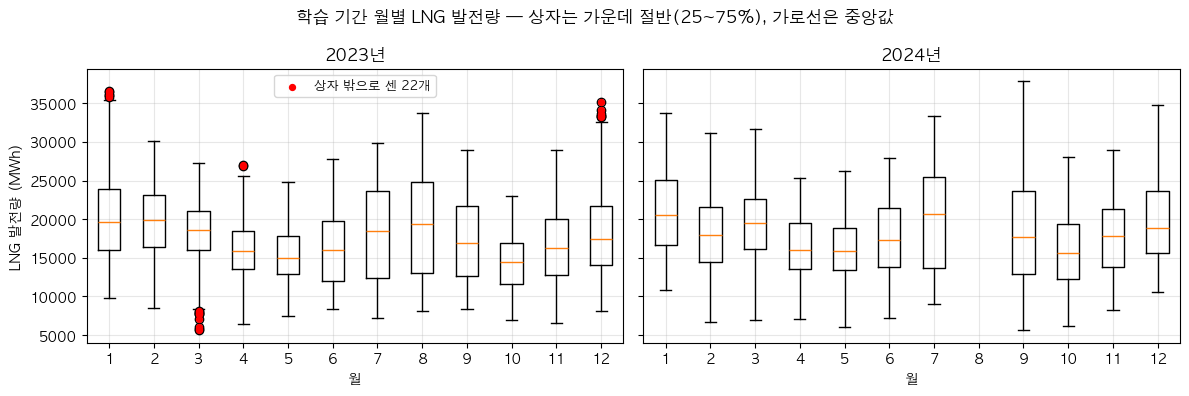

2024년 8월은 상자가 없습니다 — 물음 1에서 뺐기 때문입니다.


In [111]:
# 3단계 정제 · 3-라
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)       # 두 해를 나란히, 세로축은 같은 자로
for k, y in enumerate(학습해):
    g = train[train["year"] == y]                                # 학습 기간에서 그 해만
    자료 = [g.loc[g["month"] == m, "lng_mwh"].values for m in range(1, 13)]   # 달마다 값 묶음
    있는달 = [m for m in range(1, 13) if len(자료[m - 1]) > 0]     # 값이 있는 달만 (2024년 8월은 비어 있다)
    ax[k].boxplot([자료[m - 1] for m in 있는달], positions=있는달)  # 달마다 상자 하나
    ax[k].set_xticks(range(1, 13)); ax[k].set_xticklabels(range(1, 13))       # 가로축을 1~12월로
    ax[k].set_title(f"{y}년"); ax[k].set_xlabel("월"); ax[k].grid(alpha=.3)
    점 = 밖[밖["year"] == y]                                      # 그 해의 상자 밖 시각 (3-가에서 만든 표)
    if len(점):
        ax[k].scatter(점["month"], 점["lng_mwh"], color="red", zorder=3, s=18,
                      label="상자 밖으로 센 22개")
        ax[k].legend(loc="upper center", fontsize=9)
ax[0].set_ylabel("LNG 발전량 (MWh)")
plt.suptitle("학습 기간 월별 LNG 발전량 — 상자는 가운데 절반(25~75%), 가로선은 중앙값")
plt.tight_layout(); plt.show()

print("2024년 8월은 상자가 없습니다 — 물음 1에서 뺐기 때문입니다.")


## 3-마

**무엇을 보는 셀인가.** 상자 밖으로 걸린 4월 2개가 2023년 4월 18일 9시와 10시입니다. 그날 하루를 0시부터 23시까지 펴고, 같은 달 평일 같은 시각의 평균을 옆에 놓고, 그 차이를 적었습니다. 기온과 원자력도 같이 놓았습니다. 그 두 시각만 튄 것인지 하루 종일 높았던 것인지 보는 셀입니다.

**2026-09-19에 고친 것 둘.** 처음에는 「4월 평일 평균」과 비교했는데, 상자그림의 가로선이 평균이 아니라 중앙값이라는 지적을 받고 중앙값으로 바꿨습니다. 그리고 「상자밖」 칸을 넣어 어느 시각이 실제로 상자 밖으로 걸렸는지 표 안에서 보이게 했습니다.

In [112]:
# 3단계 정제 · 3-마
하루 = train[(train["ts"] >= "2023-04-18") & (train["ts"] < "2023-04-19")].copy()   # 그날 24시각
평일 = train[(train["year"] == 2023) & (train["month"] == 4) & (train["is_weekend"] == 0)]  # 같은 달 평일 전부
중앙 = 평일.groupby("hour24")["lng_mwh"].median()                # 시각마다 4월 평일 중앙값
하루["시각별 중앙값"] = 하루["hour24"].map(중앙).round(0)          # 그 중앙값을 그날 옆에 붙인다
하루["차이"] = (하루["lng_mwh"] - 하루["시각별 중앙값"]).round(0)   # 그날이 중앙값보다 얼마나 많았나
아래선, 위선 = 경계[(2023, 4)]                                   # 3-나에서 만든 그 달의 상자 위아래 선
하루["상자밖"] = ["예" if (v < 아래선 or v > 위선) else "" for v in 하루["lng_mwh"]]
표 = 하루[["hour24", "lng_mwh", "시각별 중앙값", "차이", "상자밖", "ta"]]
표.columns = ["시", "4/18 LNG", "시각별 중앙값", "차이", "상자밖", "기온"]

print(f"2023년 4월 상자의 위선은 {위선:,.0f} MWh입니다. 이 선을 넘은 시각에만 「상자밖」이 붙습니다.")
print("표의 「차이」는 다른 기준입니다 — 같은 달 평일 같은 시각의 중앙값과 비교한 것입니다.\n")
print(표.to_string(index=False))


2023년 4월 상자의 위선은 25,955 MWh입니다. 이 선을 넘은 시각에만 「상자밖」이 붙습니다.
표의 「차이」는 다른 기준입니다 — 같은 달 평일 같은 시각의 중앙값과 비교한 것입니다.

 시  4/18 LNG  시각별 중앙값    차이 상자밖  기온
  0   15327.0        14479.0   848.0         14.8
  1   13972.0        13120.0   852.0         14.6
  2   13838.0        12906.0   932.0         14.6
  3   13951.0        12759.0  1192.0         14.6
  4   14291.0        13118.0  1173.0         14.5
  5   15545.0        13984.0  1561.0         14.0
  6   17826.0        15686.0  2140.0         13.5
  7   20332.0        17168.0  3164.0         12.0
  8   24253.0        17402.0  6851.0         10.8
  9   26849.0        17254.0  9595.0     예  10.7
 10   27031.0        16612.0 10419.0     예  10.8
 11   25251.0        15688.0  9563.0         11.1
 12   22560.0        15110.0  7450.0         11.5
 13   23339.0        15992.0  7347.0         12.9
 14   22919.0        16896.0  6023.0         14.4
 15   23134.0        18055.0  5079.0         16.7
 16   22921.0        19548.0  3373.0         18.0
 17   2

## 저장 — 다음 단계가 읽을 표

**어디서 나온 셀인가.** 3단계에서 정한 것을 표에 반영해 파일로 남기는 셀입니다. 5·6·7단계 노트북은 이 파일을 읽습니다. 그래야 단계마다 원자료를 다시 읽고 붙이는 일을 되풀이하지 않고, 3단계에서 정한 것이 뒷단계에 그대로 이어집니다.

**무엇이 들어가나.** 2023·2024·2025년 시간별 표입니다. 2024년 2월 29일과 8월 한 달은 준비 ②에서 이미 빠져 있습니다. 상자 밖 22개는 남기기로 하셨으므로 그대로 들어갑니다. **태양광은 설비용량(`solar_cap_mw`)과 발전량(`solar_mwh`)을 둘 다 넣습니다** — 어느 쪽을 쓸지는 6단계에서 정하므로 둘 다 있어야 그때 비교할 수 있습니다.

**2026년은 여기 없습니다.** 적용 구간이라 9단계에서 씁니다. 그때 같은 방식으로 만들고, 5월 2일부터 17일까지를 빼는 것은 이 노트북 닫는 칸에 적어 두었습니다.

In [113]:
# 3단계 정제 · 저장
hot = os.path.join(ROOT, "data", "hot")                          # 단계 사이를 잇는 폴더
os.makedirs(hot, exist_ok=True)                                  # 없으면 만든다

태 = pd.concat([pick(load_kpx(y), "태양광", "mwh", "solar_mwh")   # 태양광 발전량도 같이 저장한다
                for y in (2023, 2024, 2025)])                    # 어느 쪽을 쓸지는 6단계에서 정한다
저장 = tbl.merge(태, on="ts", how="left")

경로 = os.path.join(hot, "clean_2023_2024_2025.csv")
저장.to_csv(경로, index=False, encoding="utf-8-sig")
print("저장했습니다 →", os.path.relpath(경로, ROOT))
print(f"  {len(저장):,}행 · 열 {len(저장.columns)}개")
for i in range(0, len(저장.columns), 5):                          # 열 이름을 다섯 개씩 끊어 찍는다
    print("   ", ", ".join(저장.columns[i:i + 5]))

print("\n해별 행 수 — 2024년이 8,016인 것은 2월 29일과 8월 한 달을 뺐기 때문입니다")
print(저장.groupby("year").size().rename("행 수").to_string())
print("\n빈 칸이 있는 열")
print(저장.isna().sum()[lambda s: s > 0].to_string() if 저장.isna().sum().sum() else "  없음")


저장했습니다 → data/hot/clean_2023_2024_2025.csv
  25,536행 · 열 13개
    ts, lng_mwh, nuke_mwh, solar_cap_mw, ta
    hm, icsr, year, month, hour24
    dow, is_weekend, solar_mwh

해별 행 수 — 2024년이 8,016인 것은 2월 29일과 8월 한 달을 뺐기 때문입니다
year
2023    8760
2024    8016
2025    8760

빈 칸이 있는 열
  없음
